# Not getting the clear difference between Standardization and Normalization from CampusX's video.<br>
# So directly moving to the code part

Types of Normalization:
1) MinMax scaling: Formula is **(x - min)/(max - min)**. Scales bewteen 0 and 1.
2) Mean normalization
3) Max absolute scaling
4) Robust scaling

After Noralization, minimum value becomes 0 and maximum value becomes 1.

In [1]:
import pandas as pd
import numpy as np


In [2]:
df = pd.read_csv("25 wine_data.csv", usecols = [0, 1, 2], header = None)


In [3]:
df.head()

,0,1,2
0,1,14.23,1.71
1,1,13.20,1.78
2,1,13.16,2.36
3,1,14.37,1.95
4,1,13.24,2.59


In [4]:
df.columns = ['Label', 'Alcohol', 'Malic_acid']

In [5]:
df.sample(5)

,Label,Alcohol,Malic_acid
120,2,11.45,2.40
17,1,13.83,1.57
144,3,12.25,3.88
8,1,14.83,1.64
153,3,13.23,3.30


In [6]:
df.min()

Label          1.00
Alcohol       11.03
Malic_acid     0.74
dtype: float64

In [7]:
df.max()

Label          3.00
Alcohol       14.83
Malic_acid     5.80
dtype: float64

In [8]:
df.iloc[:5:]

,Label,Alcohol,Malic_acid
0,1,14.23,1.71
1,1,13.20,1.78
2,1,13.16,2.36
3,1,14.37,1.95
4,1,13.24,2.59


In [9]:
import seaborn as sns
import matplotlib.pyplot as plt

<AxesSubplot: xlabel='Alcohol', ylabel='Malic_acid'>

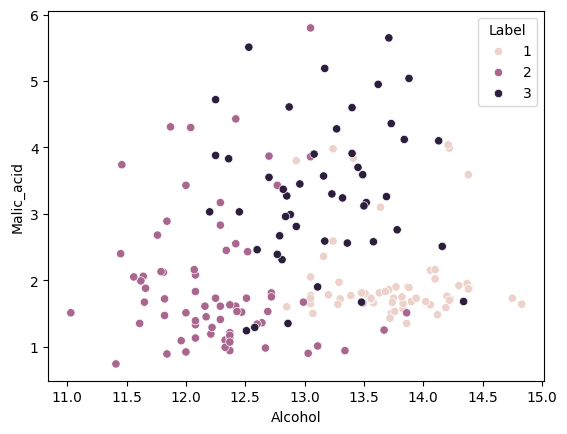

In [10]:
sns.scatterplot(x = 'Alcohol', y = 'Malic_acid', hue = 'Label', data = df)

Text(0.5, 1.0, 'Distribution of Alcohol')

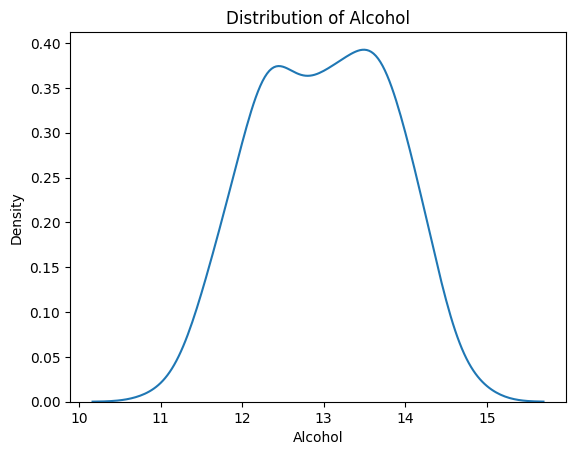

In [11]:
sns.kdeplot(x = "Alcohol", data = df)
plt.title("Distribution of Alcohol")

C:\Users\jugal\AppData\Local\Temp\ipykernel_13580\2167829647.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["Malic_acid"], hist = False)


Text(0.5, 1.0, 'Distribution of Malic acid')

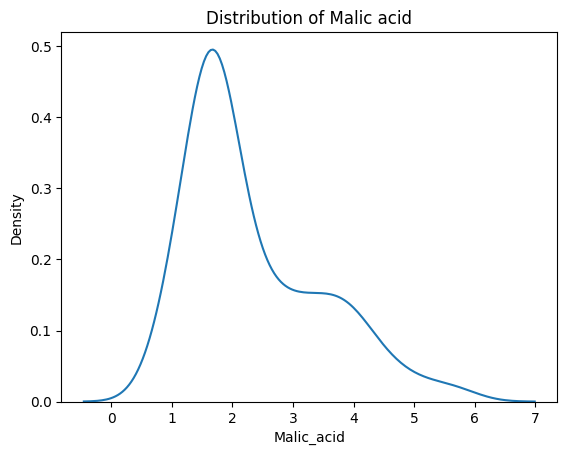

In [12]:
sns.distplot(df["Malic_acid"], hist = False)
plt.title("Distribution of Malic acid")

In [13]:
# Splitting data into x and y

x = df.iloc[:,1:3]
y = df.drop(x, axis = 'columns')

print(x.head())
print()
print(y.head())

   Alcohol  Malic_acid
0    14.23        1.71
1    13.20        1.78
2    13.16        2.36
3    14.37        1.95
4    13.24        2.59

   Label
0      1
1      1
2      1
3      1
4      1


In [14]:
from sklearn.preprocessing import MinMaxScaler

mms = MinMaxScaler()

x_scaled = mms.fit_transform(x)

In [15]:
# MinMaxScaler returns the converted output in an array so we need to convert it into an dataframe for further understanding

x_scaled_df = pd.DataFrame(x_scaled, columns = x.columns)    # It returns columns' names as 0, 1, 2 etc. So we need to explicitely define columns' names

In [16]:
x_scaled_df.head()

,Alcohol,Malic_acid
0,0.842105,0.191700
1,0.571053,0.205534
2,0.560526,0.320158
3,0.878947,0.239130
4,0.581579,0.365613


<AxesSubplot: xlabel='Alcohol', ylabel='Density'>

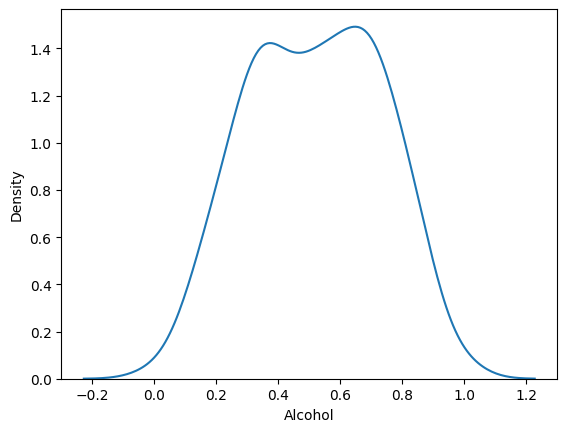

In [17]:
sns.kdeplot(x = 'Alcohol', data = x_scaled_df)

# There is no difference in the distribution of 'Alcohol' after normalization.

<AxesSubplot: xlabel='Malic_acid', ylabel='Density'>

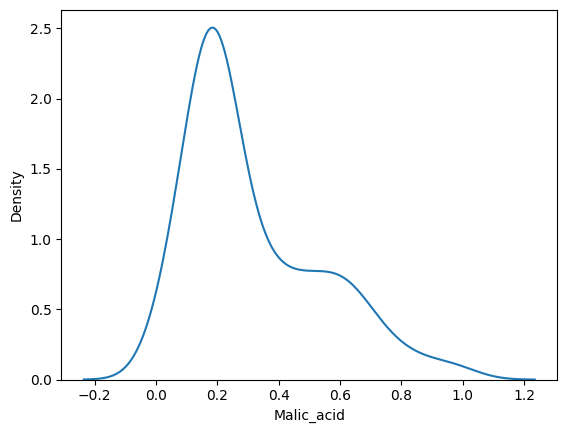

In [18]:
sns.kdeplot(x = "Malic_acid", data = x_scaled_df)

# There's no distribution in "Malic acid as wee; after normalization"

In [20]:
np.round(x.describe(), 1)

,Alcohol,Malic_acid
count,178.0,178.0
mean,13.0,2.3
std,0.8,1.1
min,11.0,0.7
25%,12.4,1.6
50%,13.0,1.9
75%,13.7,3.1
max,14.8,5.8


In [19]:
np.round(x_scaled_df.describe(), 1)    # 1 here indicates one decimal point

,Alcohol,Malic_acid
count,178.0,178.0
mean,0.5,0.3
std,0.2,0.2
min,0.0,0.0
25%,0.4,0.2
50%,0.5,0.2
75%,0.7,0.5
max,1.0,1.0


# Visualization before and after Normalization

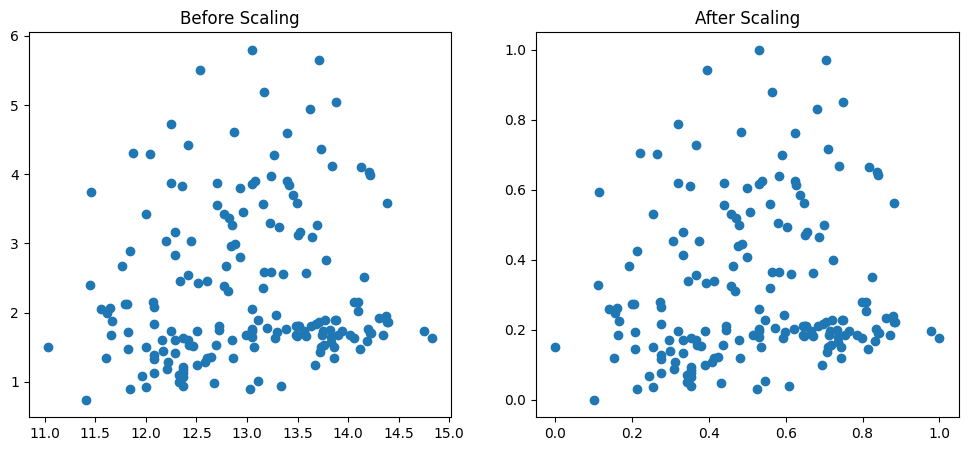

In [29]:
fig, (ax1, ax2) = plt.subplots(ncols=2, figsize=(12, 5))

ax1.scatter(df['Alcohol'], df['Malic_acid'])
ax1.set_title("Before Scaling")
ax2.scatter(x_scaled_df['Alcohol'], x_scaled_df['Malic_acid'])
ax2.set_title("After Scaling")
plt.show()

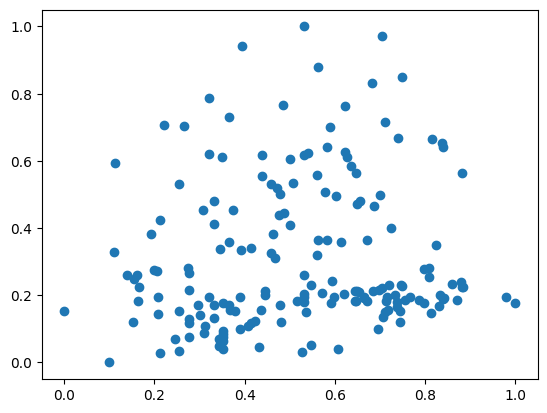

In [36]:
plt.scatter(x = 'Alcohol', y = 'Malic_acid', data = x_scaled_df)

<AxesSubplot: xlabel='Alcohol', ylabel='Malic_acid'>

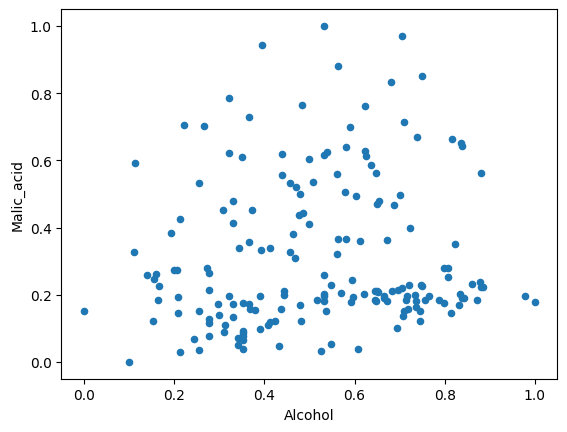

In [39]:
x_scaled_df.plot(kind = 'scatter', x = 'Alcohol', y = 'Malic_acid')

# Result:
We can see that the scale of the data has chanfed after Normalization and the distribution is same.

C:\Users\jugal\AppData\Local\Temp\ipykernel_13580\1170254825.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["Alcohol"], hist = False)
C:\Users\jugal\AppData\Local\Temp\ipykernel_13580\1170254825.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(df["Malic_acid"], hist 

<AxesSubplot: xlabel='Malic_acid', ylabel='Density'>

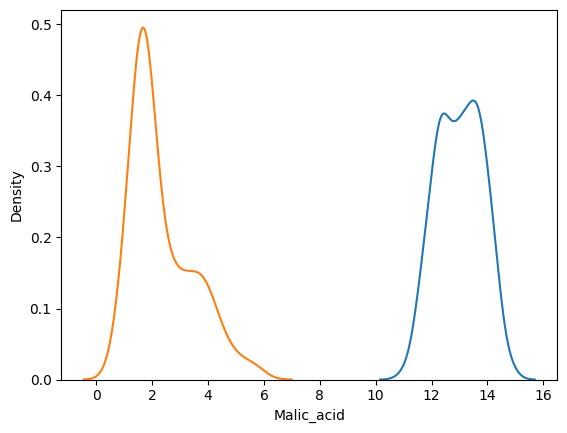

In [52]:
sns.distplot(df["Alcohol"], hist = False)
sns.distplot(df["Malic_acid"], hist = False)

C:\Users\jugal\AppData\Local\Temp\ipykernel_13580\355992330.py:1: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_scaled_df["Alcohol"], hist = False)
C:\Users\jugal\AppData\Local\Temp\ipykernel_13580\355992330.py:2: UserWarning: 

`distplot` is a deprecated function and will be removed in seaborn v0.14.0.

Please adapt your code to use either `displot` (a figure-level function with
similar flexibility) or `kdeplot` (an axes-level function for kernel density plots).

For a guide to updating your code to use the new functions, please see
https://gist.github.com/mwaskom/de44147ed2974457ad6372750bbe5751

  sns.distplot(x_scaled_df["Mal

<AxesSubplot: xlabel='Malic_acid', ylabel='Density'>

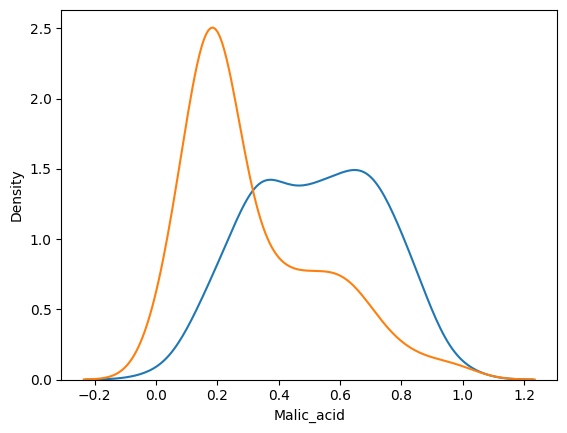

In [55]:
sns.distplot(x_scaled_df["Alcohol"], hist = False)
sns.distplot(x_scaled_df["Malic_acid"], hist = False)

# Result:

Distribution is also not changed.

# Mean normalization.

`Formula`: (x - mean)/(Xmax - Xmin)
This converts between -1 and 1. This is used rarely and there's no class for this in scikitlearn so we need to do it manually.

# MaxAbsScaling(Max Absolute Scaling):

`Formula`: x/|Xmax|
There's a class named **MaxAbsScaler** in scikit learn.<br>
It is used where we have sparse data. `Sparse` data means where there're so many zeros. It is also very rarely used.<br>
**from sklearn.preprocessing import MaxAbsScaler**

# Robust scaling

* `Formula`: (x - Xmedian)/IQR; Where `IQR = Q3 - Q1`
* Class is RobustScaler in scikit learn library. `from sklearn.preprocessing import RobustScaler`
* The speciality of Robust scaling is that it's robust to outliers.
* If there're lot of outliers generally this gives better result.


# When to use Normalization?

Before moving toward Normalization, always ask  a question that whether normalization is required?<br>
For eg. If we are gonna use algorithms like Decision tree, Random forest then we don't require.

When we already know the minimum and maximum value of our data, use Normalization.<br>
For eg: While dealing with images, the minimum and maximum value will be 0 and 255 respectively. So always use `normalization` in this case.


# Day 26 - Encoding categorical data(Ordinal encoding)